In [1]:
import glob
import os
import tempfile

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pyproj import Transformer

import GRSdriver
from GRSdriver import Sentinel2Driver

print('GRSdriver', GRSdriver.__version__)

GRSdriver 2.0.0


In [2]:
def utm_projection(crs):
    """Cartopy UTM projection of a product CRS (EPSG 326xx: north, 327xx: south)."""
    epsg = crs.to_epsg()
    return ccrs.UTM(epsg % 100, southern_hemisphere=epsg // 100 == 327)

In [3]:
data_dir = '/data/satellite/Sentinel-2/L1C'
tile, year = '31TFJ', '2022'
resolution = 20                     # m
band_idx = list(range(13))          # all the bands, as needed by GRS

odir = os.path.join(tempfile.gettempdir(), 'grsdriver_tutorial', tile)
os.makedirs(odir, exist_ok=True)

In [4]:
clon, clat = 5.10, 43.47            # Étang de Berre
width, height = 22000, 18000        # m

box = GRSdriver.SpatioTemp().wktbox(clon, clat, width=width, height=height)
aoi = gpd.GeoSeries.from_wkt([box], crs=4326)
aoi.total_bounds

array([ 4.827388, 43.307662,  5.372612, 43.631687])

In [5]:
image = glob.glob(os.path.join(data_dir, tile, '2022', '11', '20', '*.SAFE'))[0]

l1c = Sentinel2Driver(image, band_idx=band_idx, subset=aoi, resolution=resolution, resolution_angle=60)
l1c.load_product()
prod = l1c.prod
print(f'{prod.x.size} x {prod.y.size} pixels, {prod.nbytes / 1e6:.0f} MB in memory')

2246 x 1856 pixels, 667 MB in memory


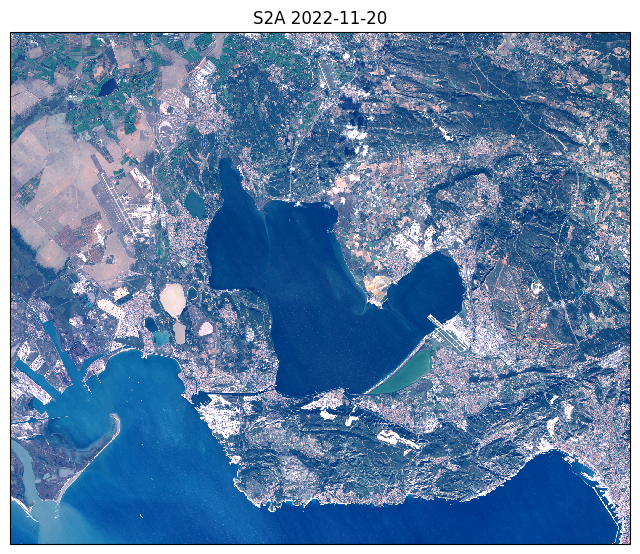

In [6]:
proj = utm_projection(prod.rio.crs)
fig = plt.figure(figsize=(8, 7))
ax = plt.axes(projection=proj)
(prod.bands.sel(wl=[665, 560, 490]) ** 0.5).plot.imshow(ax=ax, rgb='wl', robust=True, transform=proj)
ax.set_title(f'{prod.attrs["satellite"]} {prod.attrs["acquisition_date"][:10]}')
plt.show()

In [7]:
complevel = 5
def int16(scale_factor, add_offset=0.):
    return {'dtype': 'int16', 'scale_factor': scale_factor, 'add_offset': add_offset,
            '_FillValue': -32768, 'zlib': True, 'complevel': complevel}

encoding = {'bands': int16(5e-5, 0.3),     # reflectance from -1.34 to 1.94
            'vza': int16(0.01),
            'sza': int16(0.01),
            'raa': int16(0.1)}

def output_file(image):
    return os.path.join(odir, os.path.basename(image).replace('.SAFE', '.nc'))

prod.to_netcdf(output_file(image), encoding=encoding)
print(f'{os.path.getsize(output_file(image)) / 1e6:.1f} MB on disk')

66.4 MB on disk


In [8]:
images = sorted(glob.glob(os.path.join(data_dir, tile, year, '*', '*', '*.SAFE')))
# skip incomplete downloads (no metadata file)
images = [image for image in images if os.path.exists(os.path.join(image, 'MTD_MSIL1C.xml'))]

info = []
for image in images:
    l1c = Sentinel2Driver(image)
    info.append({'image': image, 'date': l1c.datetime,
                 'cloud_cover': float(l1c.metadata['CLOUD_COVERAGE_ASSESSMENT'])})
info = pd.DataFrame(info)
selection = info.loc[info.groupby(info.date.dt.month).cloud_cover.idxmin()]
print(f'{len(images)} images in {year}, {len(selection)} selected')
selection[['date', 'cloud_cover']]

91 images in 2022, 12 selected


,date,cloud_cover
0,2022-01-27 10:43:21,2.879694
2,2022-02-01 10:41:49,0.000000
12,2022-03-23 10:36:39,0.000000
17,2022-04-17 10:36:31,0.229534
30,2022-05-29 10:25:59,0.000000
34,2022-06-11 10:36:29,0.000000
41,2022-07-01 10:36:29,0.000000
56,2022-08-05 10:36:31,0.000000
70,2022-09-11 10:26:21,0.000000
76,2022-10-04 10:39:11,12.779680


In [9]:
%%time
for image in selection.image:
    if os.path.exists(output_file(image)):
        continue
    l1c = Sentinel2Driver(image, band_idx=band_idx, subset=aoi, resolution=resolution, resolution_angle=60)
    l1c.load_product()
    l1c.prod.to_netcdf(output_file(image), encoding=encoding)

CPU times: user 19min 27s, sys: 1min 14s, total: 20min 41s
Wall time: 6min 14s


In [10]:
files = [output_file(image) for image in selection.image]
datacube = xr.open_mfdataset(files, combine='nested', concat_dim='time',
                             data_vars='minimal', coords='minimal', compat='override').sortby('time')
datacube

<xarray.Dataset> Size: 16GB
Dimensions:      (time: 12, wl: 13, y: 1856, x: 2246, wl_hr: 1950)
Coordinates:
  * time         (time) datetime64[ns] 96B 2022-01-27T10:43:21 ... 2022-12-10...
  * wl           (wl) int64 104B 443 490 560 665 705 ... 865 945 1375 1610 2190
  * y            (y) float64 15kB 4.834e+06 4.834e+06 ... 4.797e+06 4.797e+06
  * x            (x) float64 18kB 6.474e+05 6.474e+05 ... 6.923e+05 6.923e+05
  * wl_hr        (wl_hr) int64 16kB 400 401 402 403 404 ... 2346 2347 2348 2349
    spatial_ref  int64 8B ...
Data variables:
    bands        (time, wl, y, x) float64 5GB dask.array<chunksize=(1, 5, 928, 1123), meta=np.ndarray>
    SRF          (time, wl, wl_hr) float64 2MB dask.array<chunksize=(1, 13, 1950), meta=np.ndarray>
    wl_true      (time, wl) float64 1kB dask.array<chunksize=(1, 13), meta=np.ndarray>
    vza          (time, wl, y, x) float64 5GB dask.array<chunksize=(1, 5, 928, 1123), meta=np.ndarray>
    raa          (time, wl, y, x) float64 5GB dask.array<chunksize=(1, 5, 928, 1123), meta=np.ndarray>
    sza          (time, y, x) float64 400MB dask.array<chunksize=(1, 1856, 2246), meta=np.ndarray>
Attributes: (12/49)
    long_name:                           CA BLUE GREEN RED VRE_1 VRE_2 VRE_3 ...
    constellation:                       Sentinel-2
    constellation_id:                    S2
    product_path:                        /data/satellite/Sentinel-2/L1C/31TFJ...
    product_name:                        S2A_MSIL1C_20220127T104321_N0400_R00...
    instrument:                          MSI
    ...                                  ...
    tile:                                31TFJ
    solar_irradiance:                    [1884.69 1959.66 1823.24 1512.06 142...
    solar_irradiance_unit:               W/m²/µm
    mean_solar_azimuth:                  163.0274631379962
    mean_solar_zenith_angle:             63.86102211720227
    acquisition_date:                    2022-01-27T10:43:21.024Z

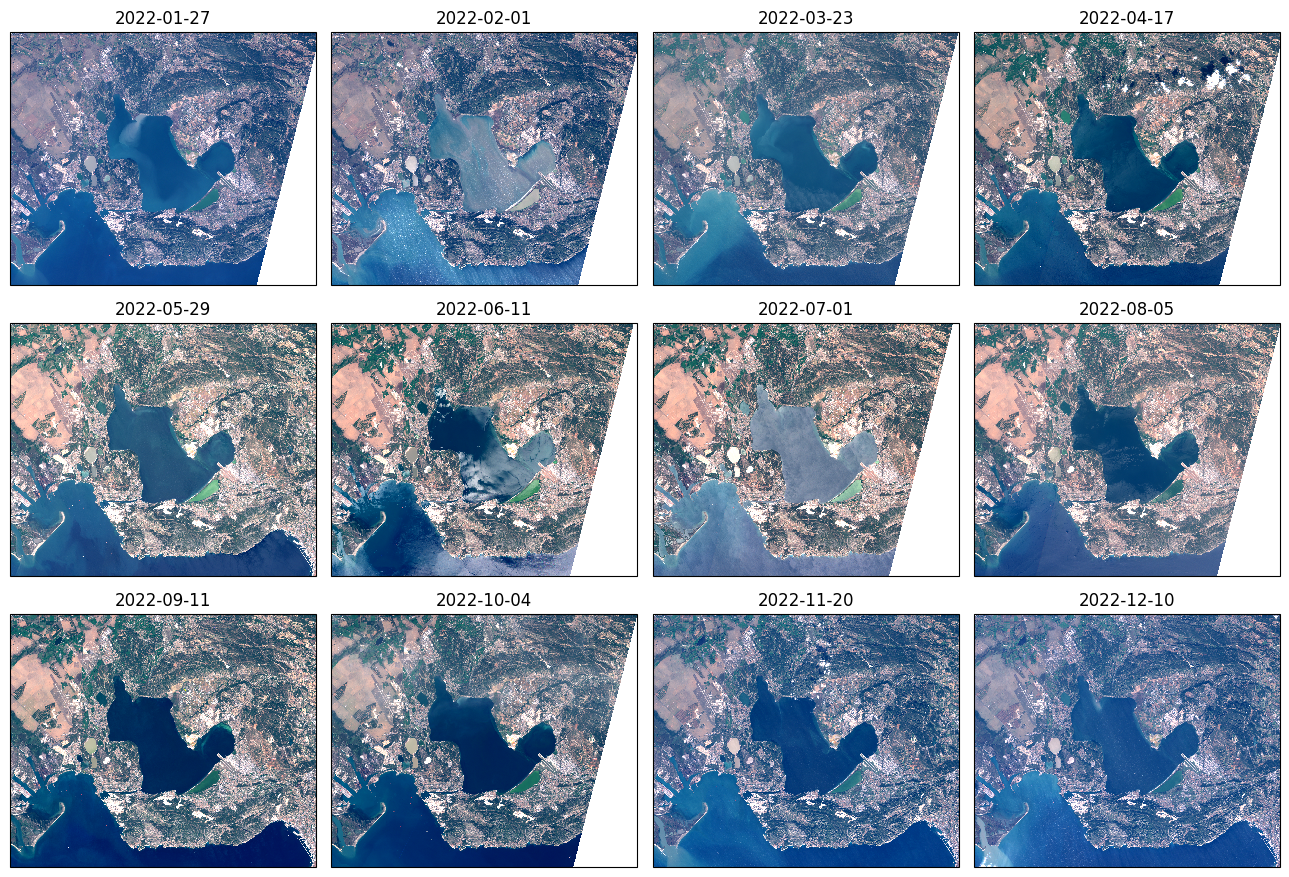

In [11]:
# int16 encoding: values can be slightly negative, clip before the square-root stretch
rgb = datacube.bands.sel(wl=[665, 560, 490]).clip(min=0) ** 0.5
fig = rgb.plot.imshow(col='time', col_wrap=4, rgb='wl', robust=True, size=3,
                      subplot_kws={'projection': proj}, transform=proj)
for ax, date in zip(fig.axs.flat, datacube.time.dt.strftime('%Y-%m-%d').values):
    ax.set_title(date)
plt.show()

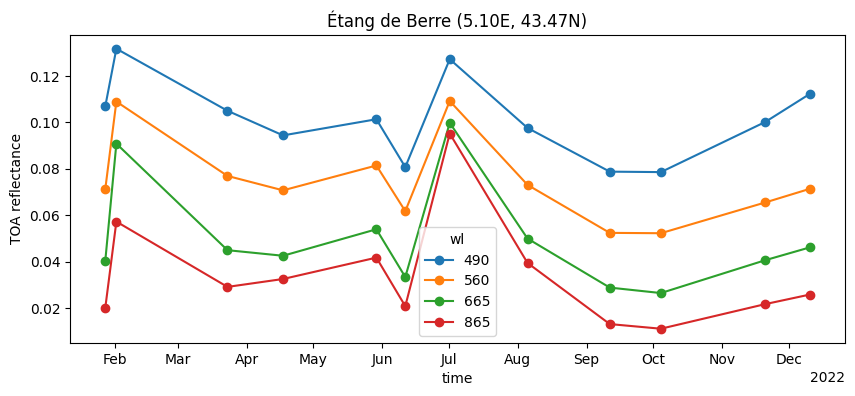

In [12]:
x, y = Transformer.from_crs(4326, datacube.rio.crs, always_xy=True).transform(5.10, 43.47)
pixel = datacube.bands.sel(x=x, y=y, method='nearest').sel(wl=[490, 560, 665, 865]).compute()

fig, ax = plt.subplots(figsize=(10, 4))
pixel.plot.line(x='time', hue='wl', marker='o', ax=ax)
ax.set_ylabel('TOA reflectance')
ax.set_title('Étang de Berre (5.10E, 43.47N)')
plt.show()